# House Prices — So sánh 6 mô hình trên 10 đặc trưng

Trong từng fold, chọn 10 cột số gốc có tương quan Pearson tuyệt đối cao nhất với SalePrice trên phần huấn luyện, theo cách tính tương quan của EDA. Bỏ qua giá trị thiếu khi tính tương quan. Xếp hạng và tiền xử lý đều học riêng trong từng fold. Chấm RMSE trên ln(SalePrice) và so sánh với kết quả cấu hình cố định trên 79 cột.

## Tham số

In [15]:
EXPERIMENT_NAME = "15-11-2026_6model_10_phuc"
RANDOM_STATE = 42
N_SPLITS = 5

MODEL_PARAMS = {
    "DummyRegressor": {"strategy": "mean"},
    "Ridge": {"alpha": 1.0, "solver": "lsqr"},
    "Random Forest": {"n_estimators": 200, "min_samples_leaf": 2, "random_state": RANDOM_STATE},
    "Lasso": {"alpha": 0.001, "max_iter": 10000},
    "XGBoost": {"n_estimators": 200, "max_depth": 4, "learning_rate": 0.05,
                "random_state": RANDOM_STATE, "n_jobs": 2},
    "SVR": {"C": 10.0, "epsilon": 0.05, "gamma": "scale"},
}
TOP_K = 10

## Import và tìm thư mục dự án

Kernel cần có `xgboost` hoặc `xgboost-cpu`.

In [16]:
import json
import sys
import warnings
from datetime import datetime, timedelta, timezone
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline

cwd = Path.cwd().resolve()
project = next(
    path for path in (cwd, *cwd.parents, cwd / "Challenge1_House Prices_ Advanced Regression")
    if (path / "src" / "prepare_data.py").is_file()
    and (path / "data" / "raw" / "train.csv").is_file()
)
sys.path.insert(0, str(project))

from src.model import make_lasso, make_svr, make_xgboost
from src.models import make_dummy, make_random_forest, make_ridge
from src.prepare_data import DATA_DIR, ID, TARGET, extract_features, make_preprocessor

## Dữ liệu và các fold

Bắt đầu từ 79 cột gốc. Trong mỗi fold, chọn 10 cột số và fit pipeline tiền xử lý trên phần huấn luyện.

In [17]:
train = pd.read_csv(DATA_DIR / "raw" / "train.csv")
X = extract_features(train)
prices = train[TARGET]
assert X.shape[1] == 79, f"Cần 79 đặc trưng gốc, hiện có {X.shape[1]}"
assert np.isfinite(prices).all() and prices.gt(0).all()
y = np.log(prices)

cv = KFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
splits = list(cv.split(X))
predictions = pd.DataFrame({ID: train[ID], "ln_SalePrice": y})
predictions["fold"] = 0
for fold, (_, valid_idx) in enumerate(splits, 1):
    predictions.loc[valid_idx, "fold"] = fold

display(predictions.groupby("fold").size().rename("Số mẫu validation").to_frame())

baseline_dir = (
    project / "experiments" / "14-11-2026_6model_79_phuc"
    / "outputs" / "20261114_224507_500186"
)
baseline_predictions = pd.read_csv(baseline_dir / "validation_predictions.csv")
assert predictions[[ID, "fold"]].equals(baseline_predictions[[ID, "fold"]])
np.testing.assert_allclose(y, baseline_predictions["ln_SalePrice"])
baseline = pd.read_csv(baseline_dir / "validation_metrics.csv").set_index("model")

features_by_fold = {}
feature_rows = []
for fold, (fit_idx, _) in enumerate(splits, 1):
    numeric = X.iloc[fit_idx].select_dtypes(include="number")
    correlations = numeric.corrwith(prices.iloc[fit_idx]).dropna()
    top = correlations.abs().sort_values(ascending=False, kind="stable").head(TOP_K)
    assert len(top) == TOP_K
    features_by_fold[fold] = top.index.tolist()
    for rank, feature in enumerate(top.index, 1):
        feature_rows.append({
            "fold": fold, "rank": rank, "feature": feature,
            "pearson_r": correlations[feature],
        })

selected = pd.DataFrame(feature_rows)
display(selected.pivot(index="rank", columns="fold", values="feature"))

,Số mẫu validation
fold,
1,292
2,292
3,292
4,292
5,292


fold,1,2,3,4,5
rank,,,,,
1,OverallQual,OverallQual,OverallQual,OverallQual,OverallQual
2,GrLivArea,GrLivArea,GrLivArea,GrLivArea,GrLivArea
3,GarageCars,GarageCars,TotalBsmtSF,GarageCars,GarageCars
4,GarageArea,GarageArea,1stFlrSF,GarageArea,GarageArea
5,TotalBsmtSF,TotalBsmtSF,GarageCars,TotalBsmtSF,TotalBsmtSF
6,1stFlrSF,1stFlrSF,GarageArea,1stFlrSF,1stFlrSF
7,FullBath,FullBath,FullBath,FullBath,FullBath
8,TotRmsAbvGrd,TotRmsAbvGrd,TotRmsAbvGrd,TotRmsAbvGrd,TotRmsAbvGrd
9,YearBuilt,YearBuilt,YearBuilt,YearBuilt,YearBuilt


## Huấn luyện và đánh giá

In [18]:
%pip install xgboost-cpu

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [19]:
factories = {
    "DummyRegressor": make_dummy,
    "Ridge": make_ridge,
    "Random Forest": make_random_forest,
    "Lasso": make_lasso,
    "XGBoost": make_xgboost,
    "SVR": make_svr,
}

fold_columns = [f"fold{i}" for i in range(1, N_SPLITS + 1)]
metric_rows = []
warning_rows = []
effective_params = {}
for name, factory in factories.items():
    estimator = factory(**MODEL_PARAMS[name])
    effective_params[name] = {key: value for key, value in estimator.get_params().items()
                              if value is not None}
    scores = []
    predictions[name] = np.nan
    started = perf_counter()
    for fold, (fit_idx, valid_idx) in enumerate(splits, 1):
        subset = X[features_by_fold[fold]]
        pipeline = make_pipeline(make_preprocessor(subset), clone(estimator))
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            fitted = pipeline.fit(subset.iloc[fit_idx], y.iloc[fit_idx])
            predicted = fitted.predict(subset.iloc[valid_idx])
        for item in caught:
            warning_rows.append({"model": name, "fold": fold,
                                 "category": item.category.__name__, "message": str(item.message)})
        predictions.loc[valid_idx, name] = predicted
        scores.append(root_mean_squared_error(y.iloc[valid_idx], predicted))

    metric_rows.append({
        "model": name,
        **dict(zip(fold_columns, scores)),
        "rmse_log_mean": np.mean(scores),
        "rmse_log_std": np.std(scores, ddof=1),
        "elapsed_seconds": perf_counter() - started,
    })

results = pd.DataFrame(metric_rows).sort_values("rmse_log_mean", ignore_index=True)
warning_table = pd.DataFrame(warning_rows, columns=["model", "fold", "category", "message"])
assert predictions[list(factories)].notna().all().all()
display(results.round(5))
if not warning_table.empty:
    display(warning_table)

comparison = results[["model", "rmse_log_mean"]].rename(
    columns={"rmse_log_mean": "rmse_log_mean_10"}
).set_index("model")
comparison["rmse_log_mean_79"] = baseline["rmse_log_mean"]
comparison["delta_10_minus_79"] = (
    comparison["rmse_log_mean_10"] - comparison["rmse_log_mean_79"]
)
display(comparison.round(5))


,model,fold1,fold2,fold3,fold4,fold5,rmse_log_mean,rmse_log_std,elapsed_seconds
0,XGBoost,0.16062,0.14661,0.18909,0.16952,0.14256,0.16168,0.01875,0.27563
1,Random Forest,0.16495,0.14539,0.19924,0.16601,0.13769,0.16266,0.02386,1.13796
2,SVR,0.18459,0.15493,0.18225,0.17943,0.15648,0.17154,0.01458,0.65143
3,Lasso,0.17065,0.14810,0.24531,0.17079,0.14180,0.17533,0.04125,0.04818
4,Ridge,0.17060,0.14778,0.24692,0.17065,0.14134,0.17546,0.04208,0.04554
5,DummyRegressor,0.43325,0.39584,0.37537,0.42101,0.36845,0.39878,0.02810,0.04919


## Biểu đồ và nhận xét

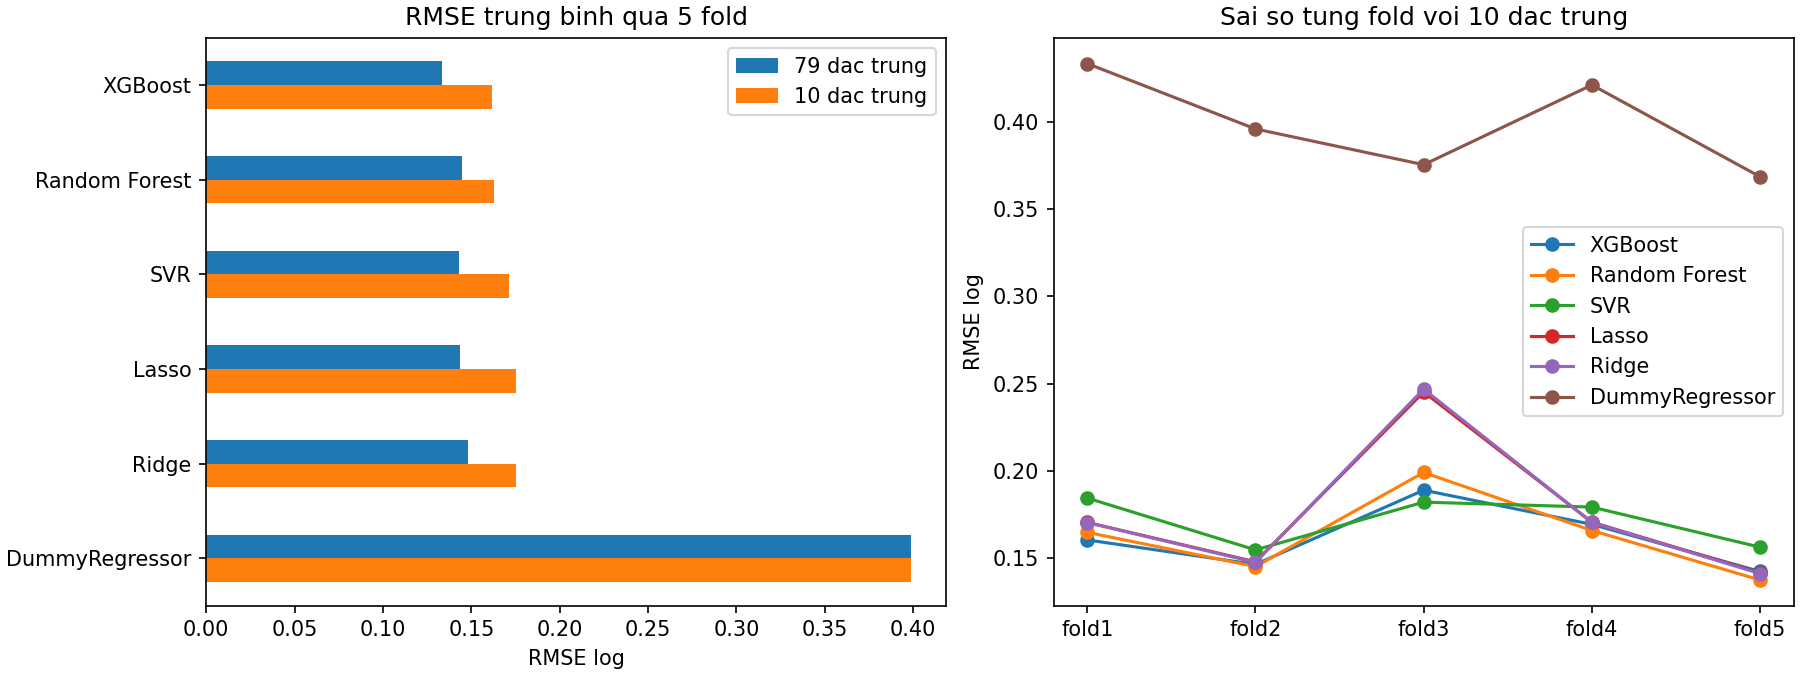

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
comparison[["rmse_log_mean_79", "rmse_log_mean_10"]].rename(columns={
    "rmse_log_mean_79": "79 dac trung", "rmse_log_mean_10": "10 dac trung",
}).plot.barh(ax=axes[0])
axes[0].invert_yaxis()
axes[0].set(xlabel="RMSE log", ylabel="", title="RMSE trung binh qua 5 fold")
for _, row in results.iterrows():
    axes[1].plot(fold_columns, row[fold_columns].to_numpy(dtype=float), marker="o", label=row["model"])
axes[1].set(ylabel="RMSE log", title="Sai so tung fold voi 10 dac trung")
axes[1].legend()
plt.show()

## Lưu kết quả

Mỗi lần chạy tạo một thư mục theo thời điểm trong `outputs/`.

In [ ]:
run_time = datetime.now(timezone(timedelta(hours=7)))
run_dir = project / "experiments" / EXPERIMENT_NAME / "outputs" / run_time.strftime("%Y%m%d_%H%M%S_%f")
image_dir = run_dir / "img"
image_dir.mkdir(parents=True, exist_ok=False)
results.to_csv(run_dir / "validation_metrics.csv", index=False)
predictions.to_csv(run_dir / "validation_predictions.csv", index=False)
warning_table.to_csv(run_dir / "validation_warnings.csv", index=False)
config = {
    "dataset": "data/raw/train.csv",
    "target_transform": "natural log",
    "feature_selection": "Top 10 absolute Pearson correlations with SalePrice on fold training rows",
    "feature_columns_by_fold": features_by_fold,
    "baseline": str(baseline_dir.relative_to(project)),
    "cv": {"n_splits": N_SPLITS, "shuffle": True, "random_state": RANDOM_STATE},
    "model_params": effective_params,
}
(run_dir / "manual_params.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
fig.savefig(image_dir / "6model_10_rmse_log.png", dpi=150)
print(run_dir.relative_to(project))
selected.to_csv(run_dir / "selected_features.csv", index=False)
comparison.to_csv(run_dir / "comparison_79_vs_10.csv")

experiments\15-11-2026_6model_10_phuc\outputs\20261115_085804_368745
